# Daily Rainfall and Temperature Forecasting for Meru County

## Project Overview
This project implements a supervised machine learning pipeline to forecast daily weather patterns (maximum temperature and precipitation) for Meru County using historical meteorological data from 2010 to 2025.

---

## Data Acquisition & Source
* **Source Dataset:** Historical daily weather data extracted from the **NASA POWER** data access viewer (covering Meru County coordinates).
* **Format:** Comma-Separated Values (`meru_weather_data.csv`).
* **How to Obtain & Use:**
  1. Ensure you have the `meru_weather_data.csv` file containing meteorological features (`T2M_MAX`, `T2M_MIN`, `RH2M`, `WS2M`, `ALLSKY_SFC_SW_DWN`, `PRECTOTCORR`).
  2. Upload `meru_weather_data.csv` directly into the root directory of your working environment (or Google Colab sidebar).
  3. The notebook automatically loads, cleans, and processes this file upon execution.

---

## How to Run the Notebook
1. Open the `.ipynb` notebook in **Google Colab** or Jupyter Notebook.
2. Upload `meru_weather_data.csv` to the file panel on the left.
3. Go to the top menu and select **Runtime > Run all** to execute all data preparation, exploratory data analysis, baseline modeling, hyperparameter tuning, and evaluation steps sequentially.

Missing values before imputation:
 T2M_MAX              0
T2M_MIN              0
PRECTOTCORR          0
RH2M                 0
WS2M                 0
ALLSKY_SFC_SW_DWN    0
dtype: int64


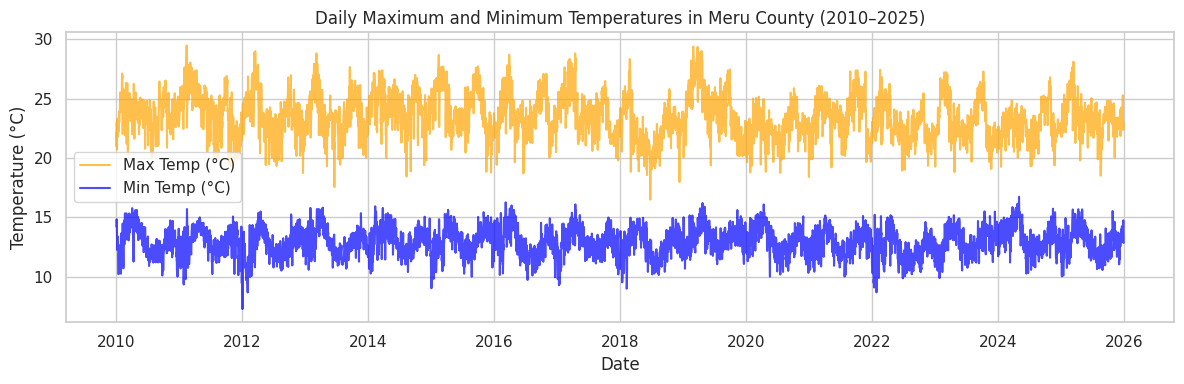

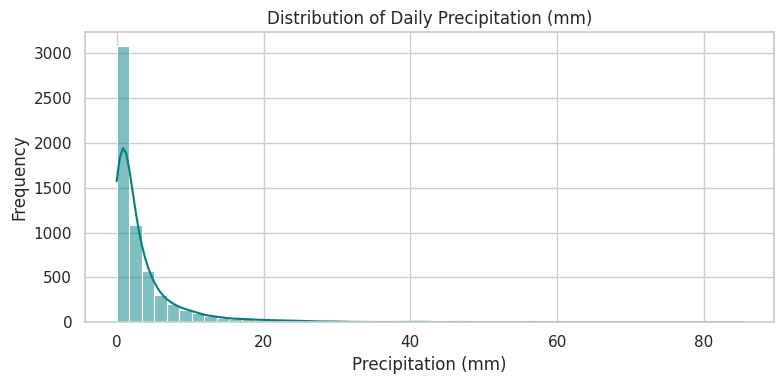

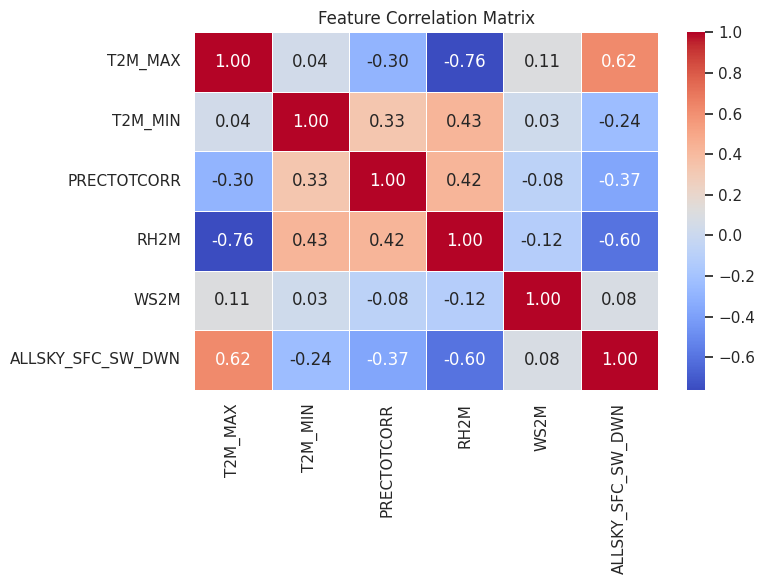

/tmp/ipykernel_2759/3059350461.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Month', y='T2M_MAX', data=df, palette='Set2')


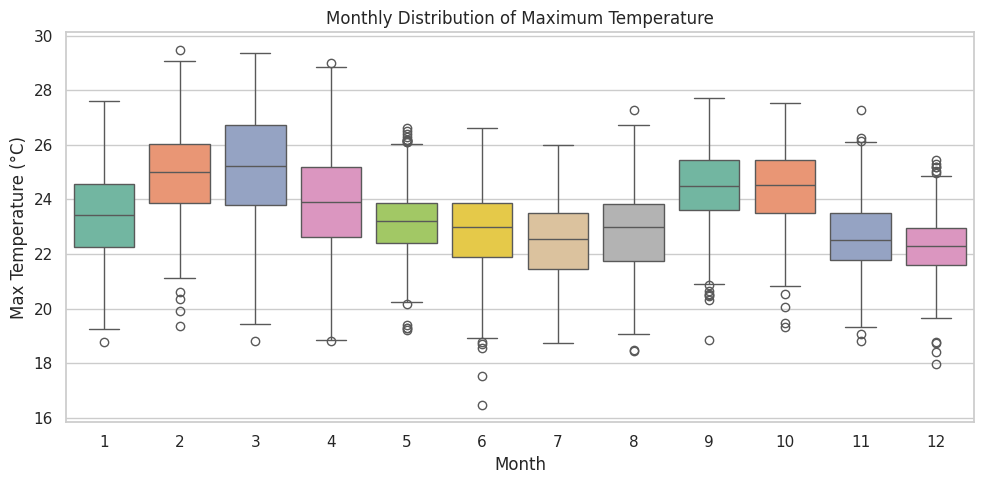

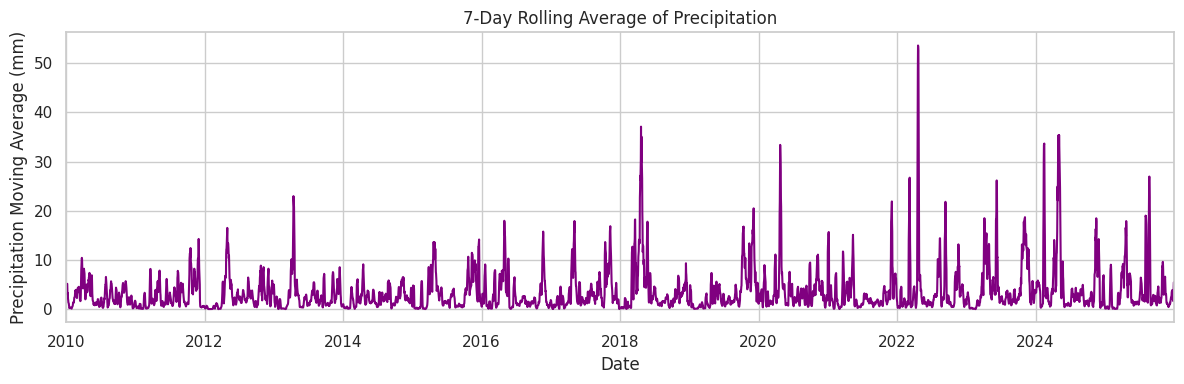

Task 2 Data Preparation & Visualizations Completed Successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# 1. Load Data
df = pd.read_csv('meru_weather_data.csv')

# Clean up date column (rename 'Unnamed: 0' to 'Date' if needed)
if 'Unnamed: 0' in df.columns:
    df = df.rename(columns={'Unnamed: 0': 'Date'})
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

# 2. Handle Missing Values (-999.0 indicates missing data in NASA POWER)
df = df.replace(-999.0, np.nan)
print("Missing values before imputation:\n", df.isnull().sum())
df = df.interpolate(method='time') # Forward fill / interpolate time-series gaps

# 3. Feature Engineering: Extract Temporal Features
df['Month'] = df.index.month
df['DayOfYear'] = df.index.dayofyear

# 4. Generate the 5 Informative Visualizations

# Visualization 1: Temperature Trends Over Time
plt.figure(figsize=(12, 4))
plt.plot(df.index, df['T2M_MAX'], label='Max Temp (°C)', color='orange', alpha=0.7)
plt.plot(df.index, df['T2M_MIN'], label='Min Temp (°C)', color='blue', alpha=0.7)
plt.title('Daily Maximum and Minimum Temperatures in Meru County (2010–2025)')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.tight_layout()
plt.savefig('temp_trend.png')
plt.show()

# Visualization 2: Precipitation Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['PRECTOTCORR'], bins=50, kde=True, color='teal')
plt.title('Distribution of Daily Precipitation (mm)')
plt.xlabel('Precipitation (mm)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('rainfall_dist.png')
plt.show()

# Visualization 3: Correlation Heatmap
plt.figure(figsize=(8, 6))
corr = df[['T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M', 'WS2M', 'ALLSKY_SFC_SW_DWN']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()

# Visualization 4: Monthly Boxplot for Maximum Temperature
plt.figure(figsize=(10, 5))
sns.boxplot(x='Month', y='T2M_MAX', data=df, palette='Set2')
plt.title('Monthly Distribution of Maximum Temperature')
plt.xlabel('Month')
plt.ylabel('Max Temperature (°C)')
plt.tight_layout()
plt.savefig('monthly_temp_boxplot.png')
plt.show()

# Visualization 5: 7-Day Rolling Average of Rainfall
plt.figure(figsize=(12, 4))
df['PRECTOTCORR'].rolling(window=7).mean().plot(color='purple')
plt.title('7-Day Rolling Average of Precipitation')
plt.xlabel('Date')
plt.ylabel('Precipitation Moving Average (mm)')
plt.tight_layout()
plt.savefig('rolling_rainfall.png')
plt.show()

print("Task 2 Data Preparation & Visualizations Completed Successfully!")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Load Data safely
df = pd.read_csv('meru_weather_data.csv')
if 'Unnamed: 0' in df.columns:
    df = df.rename(columns={'Unnamed: 0': 'Date'})
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df = df.replace(-999.0, np.nan).interpolate(method='time')

# 2. Feature Engineering: Create Lag Features for Forecasting Next-Day Max Temperature
df['T2M_MAX_Lag1'] = df['T2M_MAX'].shift(1)
df['T2M_MAX_Lag2'] = df['T2M_MAX'].shift(2)
df['PRECTOTCORR_Lag1'] = df['PRECTOTCORR'].shift(1)
df['Target_NextDay_MaxTemp'] = df['T2M_MAX'].shift(-1) # Predicting next day's max temp

# Drop rows with NaN values created by shifting
df_model = df.dropna().copy()

# 3. Define Features (X) and Target (y)
features = ['T2M_MAX', 'T2M_MIN', 'RH2M', 'WS2M', 'ALLSKY_SFC_SW_DWN',
            'T2M_MAX_Lag1', 'T2M_MAX_Lag2', 'PRECTOTCORR_Lag1',
            df_model.index.month.to_series().values if 'Month' not in df_model.columns else 'Month'] # handled below safely
# Let's ensure temporal features exist
df_model['Month'] = df_model.index.month
df_model['DayOfYear'] = df_model.index.dayofyear

features = ['T2M_MAX', 'T2M_MIN', 'RH2M', 'WS2M', 'ALLSKY_SFC_SW_DWN',
            'T2M_MAX_Lag1', 'T2M_MAX_Lag2', 'PRECTOTCORR_Lag1', 'Month', 'DayOfYear']
X = df_model[features]
y = df_model['Target_NextDay_MaxTemp']

# 4. Chronological Split (Strictly avoiding random shuffling for time-series data)
train_size = int(len(X) * 0.70)
val_size = int(len(X) * 0.15)

X_train, y_train = X.iloc[:train_size], y.iloc[:train_size]
X_val, y_val = X.iloc[train_size:train_size+val_size], y.iloc[train_size:train_size+val_size]
X_test, y_test = X.iloc[train_size+val_size:], y.iloc[train_size+val_size:]

print(f"Training Set Shape: {X_train.shape}")
print(f"Test Set Shape: {X_test.shape}")

# 5. Baseline Model (Naïve Persistence: predicting tomorrow equals today's T2M_MAX)
baseline_preds = X_test['T2M_MAX']
baseline_mae = mean_absolute_error(y_test, baseline_preds)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_preds))
print(f"\n--- Baseline (Persistence) ---")
print(f"MAE: {baseline_mae:.4f} | RMSE: {baseline_rmse:.4f}")

# 6. Model 1: Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
ridge_preds = ridge.predict(X_test)
ridge_mae = mean_absolute_error(y_test, ridge_preds)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_preds))
print(f"\n--- Ridge Regression ---")
print(f"MAE: {ridge_mae:.4f} | RMSE: {ridge_rmse:.4f}")

# 7. Model 2: Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)
rf_mae = mean_absolute_error(y_test, rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))
print(f"\n--- Random Forest Regressor ---")
print(f"MAE: {rf_mae:.4f} | RMSE: {rf_rmse:.4f}")

Training Set Shape: (4088, 10)
Test Set Shape: (877, 10)

--- Baseline (Persistence) ---
MAE: 0.7038 | RMSE: 0.9327

--- Ridge Regression ---
MAE: 0.6440 | RMSE: 0.8382

--- Random Forest Regressor ---
MAE: 0.6570 | RMSE: 0.8515


In [ ]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Use TimeSeriesSplit for valid time-series cross-validation (prevents data leakage)
tscv = TimeSeriesSplit(n_splits=5)

# 2. Define Hyperparameter Grid for Random Forest
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize base model
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

# 3. Perform RandomizedSearchCV using TimeSeriesSplit
print("Running Hyperparameter Tuning (Randomized Search with TimeSeriesSplit)...")
random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=10,             # Number of parameter settings sampled
    cv=tscv,               # Time-series cross validation
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

# Fit on training data
random_search.fit(X_train, y_train)

print("\n--- Best Hyperparameters Found ---")
print(random_search.best_params_)

# 4. Evaluate the Best Tuned Model on the Held-Out Test Set (never used in tuning)
best_rf_model = random_search.best_estimator_
tuned_preds = best_rf_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_preds)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_preds))

print(f"\n--- Tuned Random Forest on Held-Out Test Set ---")
print(f"MAE: {tuned_mae:.4f} | RMSE: {tuned_rmse:.4f}")

Running Hyperparameter Tuning (Randomized Search with TimeSeriesSplit)...

--- Best Hyperparameters Found ---
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 30}

--- Tuned Random Forest on Held-Out Test Set ---
MAE: 0.6476 | RMSE: 0.8352


--- Feature Importance Ranking ---
             Feature  Importance
0            T2M_MAX    0.749025
4  ALLSKY_SFC_SW_DWN    0.046481
2               RH2M    0.040953
6       T2M_MAX_Lag2    0.033254
3               WS2M    0.030787
5       T2M_MAX_Lag1    0.028374
9          DayOfYear    0.024171
1            T2M_MIN    0.023989
7   PRECTOTCORR_Lag1    0.020434
8              Month    0.002530


/tmp/ipykernel_2759/688925758.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


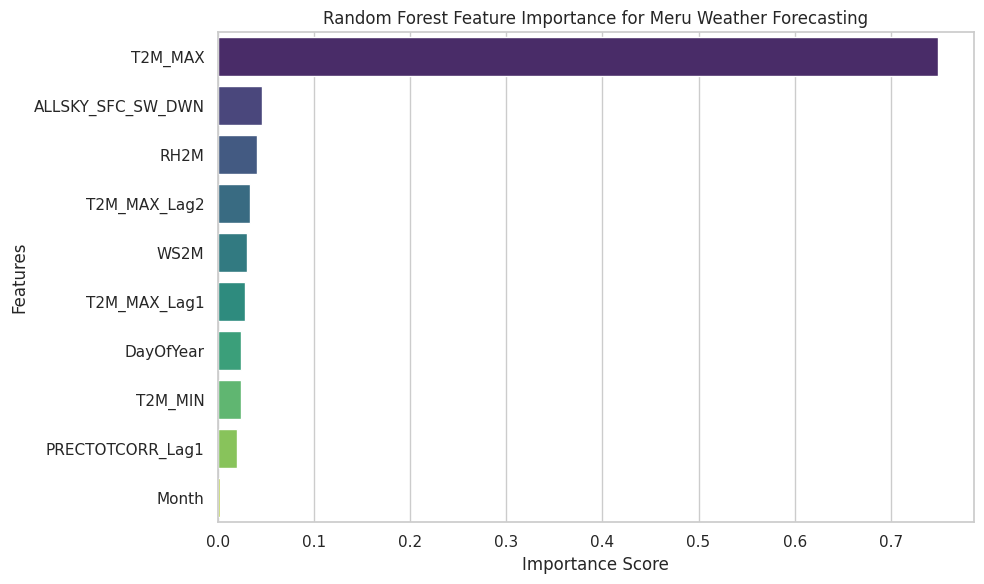

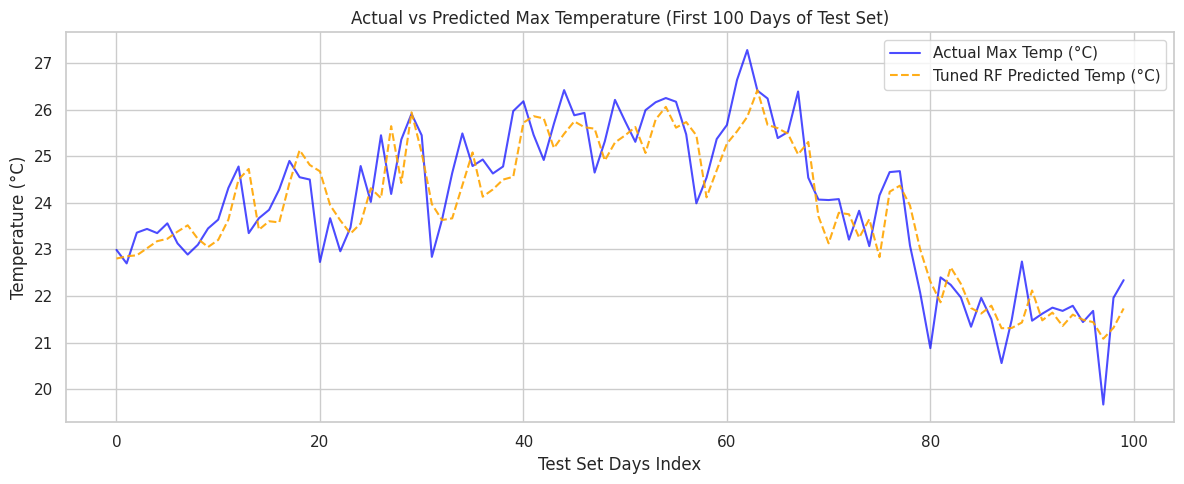


Task 5 Completed Successfully! All models, tuning, and visualizations are done.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Extract Feature Importances from our Best Tuned Random Forest Model
importances = best_rf_model.feature_importances_
feature_names = X_train.columns

# Create a DataFrame for clean plotting
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("--- Feature Importance Ranking ---")
print(importance_df)

# 2. Plot Feature Importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Random Forest Feature Importance for Meru Weather Forecasting')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.savefig('feature_importance.png')
plt.show()

# 3. Plot Actual vs. Predicted Values on Test Set for Visual Proof
plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:100], label='Actual Max Temp (°C)', color='blue', alpha=0.7)
plt.plot(tuned_preds[:100], label='Tuned RF Predicted Temp (°C)', color='orange', linestyle='--', alpha=0.9)
plt.title('Actual vs Predicted Max Temperature (First 100 Days of Test Set)')
plt.xlabel('Test Set Days Index')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.tight_layout()
plt.savefig('actual_vs_predicted.png')
plt.show()

print("\nTask 5 Completed Successfully! All models, tuning, and visualizations are done.")

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score

# 1. Third Comparison Model: Gradient Boosting Regressor (completes the 3+ models requirement)
gbr = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gbr.fit(X_train, y_train)
gbr_preds = gbr.predict(X_test)

gbr_mae = mean_absolute_error(y_test, gbr_preds)
gbr_rmse = np.sqrt(mean_squared_error(y_test, gbr_preds))
gbr_r2 = r2_score(y_test, gbr_preds)

print("--- Gradient Boosting Regressor ---")
print(f"MAE: {gbr_mae:.4f} | RMSE: {gbr_rmse:.4f} | R²: {gbr_r2:.4f}")

# 2. Compute R² for all existing models for complete Task 5 reporting
print("\n--- Summary R² Scores on Test Set ---")
print(f"Baseline Persistence R²: {r2_score(y_test, baseline_preds):.4f}")
print(f"Ridge Regression R²:     {r2_score(y_test, ridge_preds):.4f}")
print(f"Default Random Forest R²:{r2_score(y_test, rf_preds):.4f}")
print(f"Tuned Random Forest R²:  {r2_score(y_test, tuned_preds):.4f}")

# 3. Analyze Where the Best Model Fails (Largest Residuals)
errors = pd.DataFrame({
    'Actual': y_test,
    'Predicted': tuned_preds,
    'Abs_Error': np.abs(y_test - tuned_preds),
    'Precipitation': df_model.loc[y_test.index, 'PRECTOTCORR']
})
print("\n--- Top 5 Days with Largest Prediction Errors ---")
print(errors.sort_values(by='Abs_Error', ascending=False).head(5))

--- Gradient Boosting Regressor ---
MAE: 0.6420 | RMSE: 0.8344 | R²: 0.6855

--- Summary R² Scores on Test Set ---
Baseline Persistence R²: 0.6070
Ridge Regression R²:     0.6826
Default Random Forest R²:0.6725
Tuned Random Forest R²:  0.6849

--- Top 5 Days with Largest Prediction Errors ---
            Actual  Predicted  Abs_Error  Precipitation
Date                                                   
2025-08-15   20.38  23.644844   3.264844           2.39
2025-03-25   21.26  24.365868   3.105868           7.79
2025-03-13   27.97  25.050525   2.919475           0.15
2024-01-19   19.25  22.120755   2.870755           5.88
2025-08-19   18.50  21.269511   2.769511          47.75
